In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
from tqdm import tqdm
from scipy.signal import correlate
from scipy.stats import multivariate_normal
import os
import sys
import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib

import plotly.graph_objects as go

from scipy.ndimage import gaussian_filter

module_path = os.path.abspath(os.path.join('..'))
if module_path not in sys.path:
    sys.path.append(module_path)

from GLOBAL.ground_truths import *
from GLOBAL.torque import *
from GLOBAL.filters import *

#max_angle = 1000000 * np.pi / 180

with np.load("../GLOBAL/data.npz") as data:
    x_data=data['x_data']
    y_data=data['y_data']

n_trajectories = 2
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

def resample_spline(mean, cov):
    mean_resampled = np.repeat(mean, 2)
    diag_cov = np.diag(cov)
    diag_cov = np.repeat(diag_cov, 2)
    cov_resampled = np.diag(diag_cov)
    return mean_resampled, cov_resampled

Loading satellites/
Aspect ratio:  5
Ratio of rotational diffusion:  0.06769699908603415
Ratio of orthogonal diffusion:  0.7664558871581453


# Find proposal

In [2]:
def plot_torques(MEANS, COVS, n_knots=None, n_samples=10000, n_phis = 200, n_examples=0, torque_scale=50):
    #plt.figure(figsize=(4, 4))

    #MEANS = [m[1:] for m in MEANS]
    #COVS = [c[1:,1:] for c in COVS]
    
    phi = np.linspace(-np.pi * 0.1, 2.1 * np.pi, n_phis)
    phi_draw = phi * 180 / np.pi

    use = -1
    sample_mean = np.mean(MEANS[use:], axis=0)
    sample_cov = np.mean(np.array(COVS[use:]), axis=0)

    TORQUES = []

    SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, n_samples)


    for s in SAMPLES:
        TORQUES.append(TORQUE_FILTER(phi, s))

    TORQUES = np.array(TORQUES)

    Tmax = torque_scale
    Tmin = -torque_scale

    bins = np.linspace(Tmin, Tmax, n_phis)

    extent = [phi_draw.min(), phi_draw.max(), Tmin, Tmax]
    def hist1d(x):
        hist = np.histogram(x, bins=bins, density=True)[0]
        return hist / hist.max()

    density = np.apply_along_axis(hist1d, axis=0, arr=TORQUES, )

    density_ = gaussian_filter(density, (0.0,0))
    #plt.figure(dpi=300)
    cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["white","yellowgreen"])
    plt.imshow(density_, extent=extent, aspect='auto', origin='lower', cmap=cmap)

    torque_mean = np.mean(TORQUES, axis=0)
    torque_mode = bins[np.argmax(density_, axis=0)]
    torque_std = np.std(TORQUES, axis=0)

    torque_true = TORQUE(phi, ALPHAS)

    #if n_knots is not None:
    #    phi_knots = np.linspace(0, np.pi, n_knots+2)[1:-1]
    #    torque_knots = TORQUE(phi_knots, ALPHAS)
    #
    #    plt.scatter(phi_knots, torque_knots, c='r', s=10)
    #    #for phi_ in phi_knots:
    #    #    plt.axvline(phi_, color='k', alpha=0.5, lw=0.5, ls='--')

    
    for i in range(n_examples):

        SAMPLES = np.random.multivariate_normal(sample_mean, sample_cov, 1)

        TORQUES = []
        for s in SAMPLES:
            TORQUES.append(TORQUE_FILTER(phi, s))
        
        plt.plot(phi_draw, TORQUES[0], lw=1, alpha=1, ls='--', c='darkgreen')

    col='olivedrab'
    qtil = 2.575829
    
    plt.plot(phi_draw, torque_mean - qtil*torque_std, ':', lw=0.7, c=col)
    plt.plot(phi_draw, torque_mean + qtil*torque_std, ':', lw=0.7, c=col)
    #plt.plot(phi, torque_mode, '--', lw=0.7, alpha=1, c=col)
    #plt.plot(phi, torque_true, '-', lw=2, alpha=1, c='r')
    plt.axvline(0, color='k', lw=2)
    plt.axvline(360, color='k', lw=2)
    plt.grid()
    plt.ylim(Tmin, Tmax)
    plt.xticks(np.arange(0, 360+1, 90))

    

In [3]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

In [4]:
class MultivariateGaussian(nn.Module):
    def __init__(self, dim):
        super(MultivariateGaussian, self).__init__()
        self.mean = nn.Parameter(torch.zeros(dim))
        self.cov_factor = nn.Parameter(1500*torch.eye(dim))
        self.normalization = nn.Parameter(torch.zeros(1))
        self.dim = dim

    def forward(self, x):
        cov_matrix = self.cov_factor @ self.cov_factor.T + torch.eye(self.dim) * 1e-6  # Ensure positive semi-definiteness
        dist = torch.distributions.MultivariateNormal(self.mean, covariance_matrix=cov_matrix)
        return dist.log_prob(x) + self.normalization

In [5]:
def learn(progression=range(20), sample_count=1024 // 64,
          torque_scale=200,
          max_angle = 90 * np.pi / 180,
          particle_count=100,
          clip_parameters=1000, mixing_ratio=0.8,
          search_size=1,
          smoothing_factor=1.0,
          fit_lr = 10,
         ):
    
    global mean, cov, ALL_COORDS, ALL_TARGET_DENSITIES, ALL_LIKELIHOODS, count
    for prog in tqdm(progression):

        ''' GENERATE NEW TEST SAMPLES '''

        distribution = multivariate_normal(mean=mean, cov=search_size*cov, allow_singular=False)
        coords = distribution.rvs(sample_count)
        weights = distribution.pdf(coords)

        ''' EVALUATE POSTERIOR AT TEST POINTS '''

        logl, _, _ = calc_logl_core(x_data, y_data, dt,
                                    PE, DT, DR, FORCE_STRENGTH,
                                    coords, torque_limit=max_angle,
                                    n_particles=particle_count,
                                    clip_parameters=clip_parameters,
                                    )
        
        ALL_COORDS = np.concatenate((ALL_COORDS, coords))
        ALL_TARGET_DENSITIES = np.concatenate((ALL_TARGET_DENSITIES, logl))

        t_ALL_COORDS = torch.tensor(ALL_COORDS, dtype=torch.float32)
        t_WEIGHTS = torch.tensor(weights, dtype=torch.float32)
        t_ALL_TARGET_DENSITIES = torch.tensor(ALL_TARGET_DENSITIES, dtype=torch.float32)
        t_ALL_TARGET_DENSITIES -= t_ALL_TARGET_DENSITIES.max()

        ''' CALULATE NEW MEAN AND COVARIANCE'''

        model = MultivariateGaussian(dim=ndims)
        optimizer = optim.Adam(model.parameters(), lr=fit_lr)
        num_epochs = 100
        
        loss_function = torch.nn.MSELoss()
        loss_function = torch.nn.KLDivLoss(log_target=True)

        cov_old = cov.copy()
        mean_old = mean.copy()

        for epoch in range(num_epochs):
            model.train()
            optimizer.zero_grad()
            
            predicted_log_probs = model(t_ALL_COORDS)
            loss = loss_function(predicted_log_probs, t_ALL_TARGET_DENSITIES)
            loss.backward()
            optimizer.step()
            
            if (epoch + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

        cov = (model.cov_factor @ model.cov_factor.T).detach().numpy()
        mean = model.mean.detach().numpy()

        if np.any(np.isnan(cov)):
            cov = cov_old
            mean = mean_old

        

        # (Stabilize the fit by mixing the old and new parameters)
        mixing_ratio = mixing_ratio
        mean = mixing_ratio * mean + (1 - mixing_ratio) * mean_old
        cov = mixing_ratio * cov + (1 - mixing_ratio) * cov_old

        ''' STORE PROGRESS '''

        COVS.append(cov.copy())
        MEANS.append(mean.copy())

        
        plt.figure(dpi=120, figsize=(5, 5))

        ''' PLOT LEFT '''

        plt.subplot(2, 2, 1)
        plt.gca().set_facecolor('silver')
        chan = np.exp(ALL_TARGET_DENSITIES.copy() - ALL_TARGET_DENSITIES.max())
        plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
        plt.axvline(centers[0], color='r', linestyle='--', lw=1)
        plt.axhline(centers[1], color='r', linestyle='--', lw=1)
        plot_cov_ellipse(mean, cov, color='w')

        ''' PLOT RIGHT '''

        plt.subplot(2, 2, 2)
        plt.gca().set_facecolor('silver')
        #chan = np.exp(ALL_TARGET_DENSITIES/10)
        chan = ALL_TARGET_DENSITIES.copy()
        plt.hexbin((ALL_COORDS)[:, d0], (ALL_COORDS)[:, d1], C=chan, gridsize=32, reduce_C_function=np.max)
        plt.axvline(centers[0], color='r', linestyle='--', lw=1)
        plt.axhline(centers[1], color='r', linestyle='--', lw=1)
        plot_cov_ellipse(mean, cov, color='w')


        ''' PLOT CONVERGENCE '''

        plt.subplot(2, 2, 3)

        COVS_flat = [cov_.copy() for cov_ in COVS]
        for cov_ in COVS_flat:
            np.fill_diagonal(cov_, np.nan)
        COVS_flat = [cov_.flatten() for cov_ in COVS]

        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'red', label='Covariances')

        COVS_flat = [np.diagonal(cov) for cov in COVS]
        COVS_flat = np.stack(COVS_flat, axis=0)
        plt.semilogy(np.abs(COVS_flat), 'blue', label='Diagonals')
        plt.xlabel("Iteration")
        plt.ylabel("Covariance matrix element")

        ''' PLOT POSTERIOR TORQUE '''

        plt.subplot(2, 2, 4)
        plot_torques(MEANS, COVS, n_knots=ndims-1, torque_scale=torque_scale)
        plt.tight_layout()
        plt.savefig(f"img/proposal_convergence{count}.png", dpi=300)
        plt.show()
        count += 1

# Learning

## Initial Run

  0%|                                       | 0/50 [00:00<?, ?it/s]~\anaconda3\envs\abp2\Lib\site-packages\torch\nn\functional.py:2994: UserWarning: reduction: 'mean' divides the total loss by both the batch size and the support size.'batchmean' divides only by the batch size, and aligns with the KL div math definition.'mean' will be changed to behave the same as 'batchmean' in the next major release.
  warnings.warn(


Epoch [100/100], Loss: -0.3231


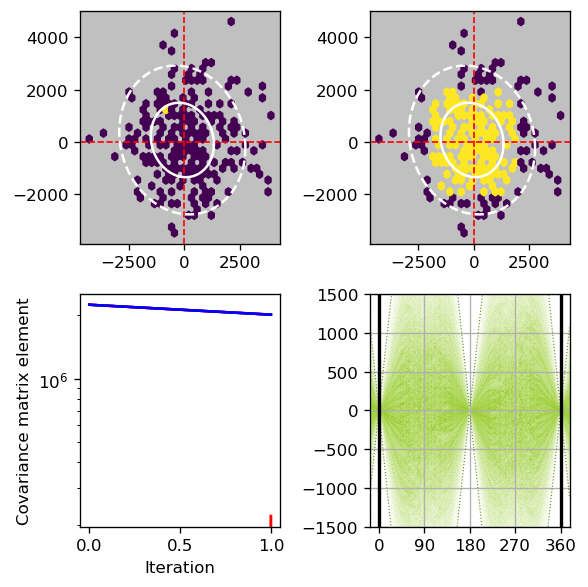

  2%|▌                              | 1/50 [00:14<11:51, 14.52s/it]~\anaconda3\envs\abp2\Lib\site-packages\torch\nn\functional.py:2994: UserWarning: reduction: 'mean' divides the total loss by both the batch size and the support size.'batchmean' divides only by the batch size, and aligns with the KL div math definition.'mean' will be changed to behave the same as 'batchmean' in the next major release.
  warnings.warn(


Epoch [100/100], Loss: -0.1620


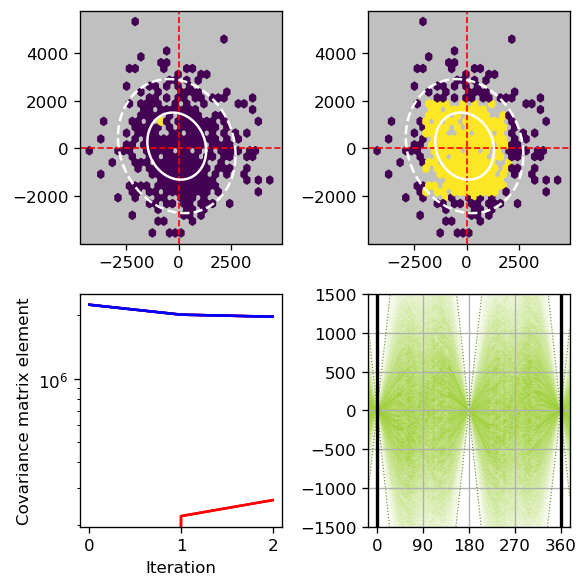

  4%|█▏                             | 2/50 [00:19<07:00,  8.76s/it]

Epoch [100/100], Loss: -0.1080


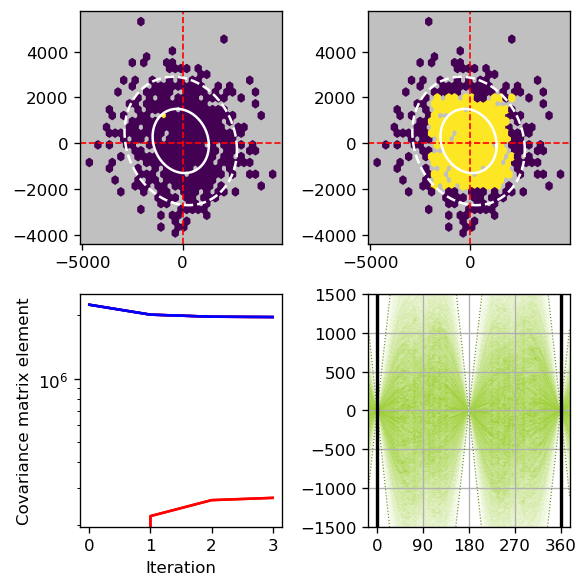

  6%|█▊                             | 3/50 [00:23<05:12,  6.64s/it]

Epoch [100/100], Loss: -0.1460


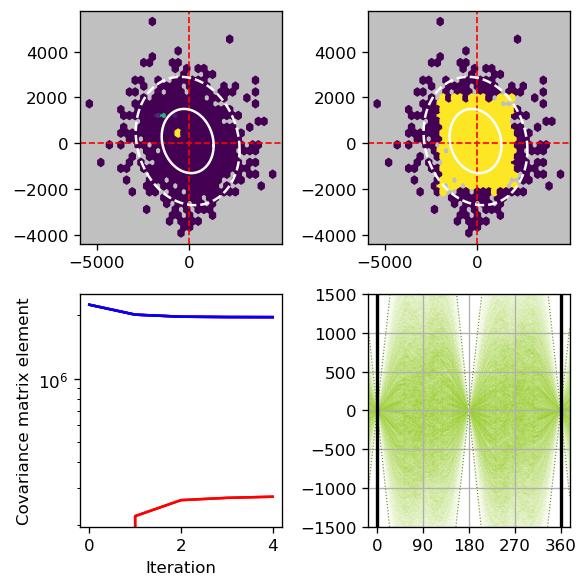

  8%|██▍                            | 4/50 [00:28<04:31,  5.90s/it]

Epoch [100/100], Loss: -0.1168


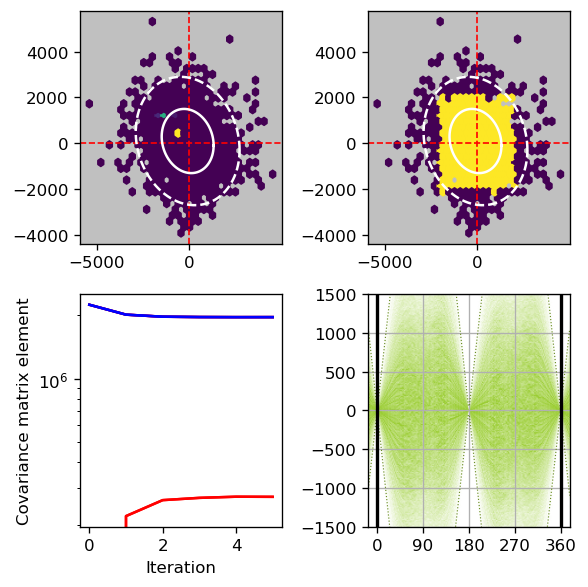

 10%|███                            | 5/50 [00:32<04:02,  5.38s/it]

Epoch [100/100], Loss: -0.0974


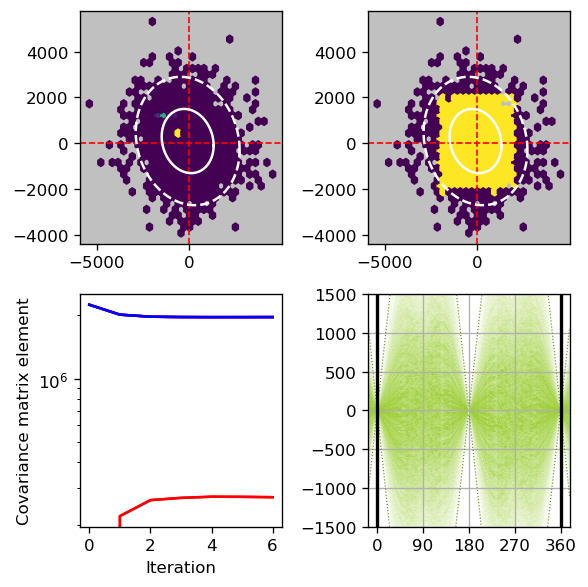

 12%|███▋                           | 6/50 [00:36<03:40,  5.02s/it]

Epoch [100/100], Loss: -0.0839


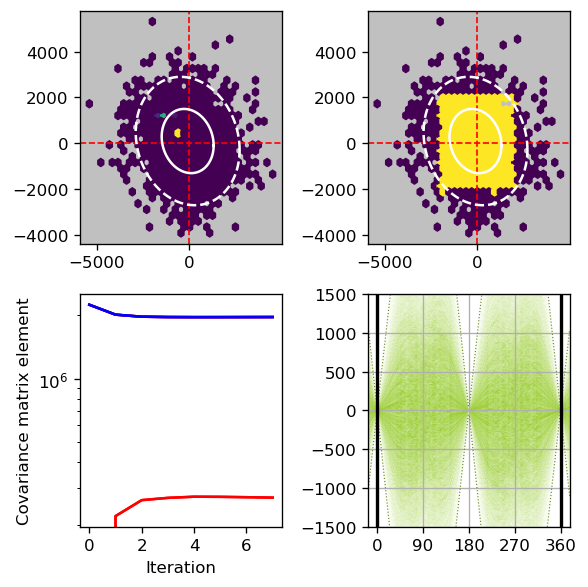

 14%|████▎                          | 7/50 [00:44<04:34,  6.39s/it]


SystemError: CPUDispatcher(<function calc_logl_core at 0x0000025C5DCD02C0>) returned a result with an exception set

In [6]:
# Set up base run

d0 = 0
d1 = 1

n_trajectories = 10
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

clipping = 2000

search_size = 1
initial_radius = 1500
ndims = 2
centers = np.zeros(ndims)
mean = centers.copy()
cov = np.eye(ndims) * initial_radius**2

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(progression=range(50),
      sample_count=1024//4,
      particle_count=400,
      torque_scale=1500,
      clip_parameters=clipping,
      search_size=search_size,
      mixing_ratio=0.8,
      smoothing_factor=1.,
      max_angle = 10 * np.pi / 180,
      fit_lr = 1,
      )

mean_1 = mean.copy()
cov_1 = cov.copy()

np.save("mean_1.npy", mean_1)
np.save("cov_1.npy", cov_1)

In [ ]:
STOP

# Refinement 1

In [ ]:
# Refinement of the torque function

mean_1 = np.load("mean_1.npy")
cov_1 = np.load("cov_1.npy")

n_trajectories = 2
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

search_size = 2
ndims = 4
mean, cov = resample_spline(mean_1, cov_1)

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn()
cov_2 = cov.copy()
mean_2 = mean.copy()

np.save("mean_2.npy", mean_2)
np.save("cov_2.npy", cov_2)


# Data increase 1

In [ ]:
# Use more data

mean_2 = np.load("mean_2.npy")
cov_2 = np.load("cov_2.npy")

n_trajectories = 8
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

search_size = 2
ndims = 4
mean, cov = mean_2.copy(), cov_2.copy()

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn()
cov_3 = cov.copy()
mean_3 = mean.copy()

np.save("mean_3.npy", mean_3)
np.save("cov_3.npy", cov_3)

# Precise sampling 1

In [ ]:
# Use more data

mean_3 = np.load("mean_3.npy")
cov_3 = np.load("cov_3.npy")

n_trajectories = 8
x_data = x_data[:n_trajectories, :]
y_data = y_data[:n_trajectories, :]

search_size = 2
ndims = 4
mean, cov = mean_3.copy(), cov_3.copy()

COVS = [cov.copy()]
MEANS = [mean.copy()]

count = 0

ALL_COORDS = np.zeros((0, ndims))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

COVS = [cov.copy()]
MEANS = [mean.copy()]

learn(new_samples_only=True, sample_count=1024)
cov_4 = cov.copy()
mean_4 = mean.copy()

np.save("mean_4.npy", mean_4)
np.save("cov_4.npy", cov_4)